In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_folder = "../dataset/train_images"
df = pd.read_csv("../dataset/train.csv")

print("Number of records:", len(df))

Number of records: 3662


In [2]:
sizes = []

for image_id in df["id_code"]:
    path = os.path.join(image_folder, image_id + ".png")

    with Image.open(path) as img:
        sizes.append(img.size)

print("Images checked:", len(sizes))
print("Unique image sizes:", len(set(sizes)))

print("\nFirst 20 sizes:")
print(sizes[:20])

Images checked: 3662
Unique image sizes: 17

First 20 sizes:
[(3216, 2136), (3216, 2136), (2416, 1736), (1050, 1050), (2048, 1536), (3388, 2588), (2588, 1958), (3216, 2136), (2588, 1958), (2416, 1736), (1050, 1050), (2416, 1736), (1050, 1050), (2416, 1736), (3216, 2136), (1050, 1050), (3216, 2136), (819, 614), (2048, 1536), (1504, 1000)]


In [3]:
from collections import Counter

size_counts = Counter(sizes)

for size, count in size_counts.most_common(10):
    print(size, ":", count)

(1050, 1050) : 974
(2416, 1736) : 638
(2588, 1958) : 533
(3216, 2136) : 410
(2048, 1536) : 351
(819, 614) : 287
(3388, 2588) : 141
(1504, 1000) : 92
(1844, 1226) : 61
(4288, 2848) : 52


In [4]:
missing_images = []

for image_id in df["id_code"]:
    path = os.path.join(image_folder, image_id + ".png")

    if not os.path.exists(path):
        missing_images.append(image_id)

print("Missing images:", len(missing_images))

Missing images: 0


In [5]:
actual_images = {
    os.path.splitext(f)[0]
    for f in os.listdir(image_folder)
    if f.lower().endswith(".png")
}

csv_images = set(df["id_code"])

print("PNG files:", len(actual_images))
print("CSV records:", len(csv_images))
print("Images without labels:", len(actual_images - csv_images))

PNG files: 3662
CSV records: 3662
Images without labels: 0


Original: (3216, 2136)
Resized: (300, 300)


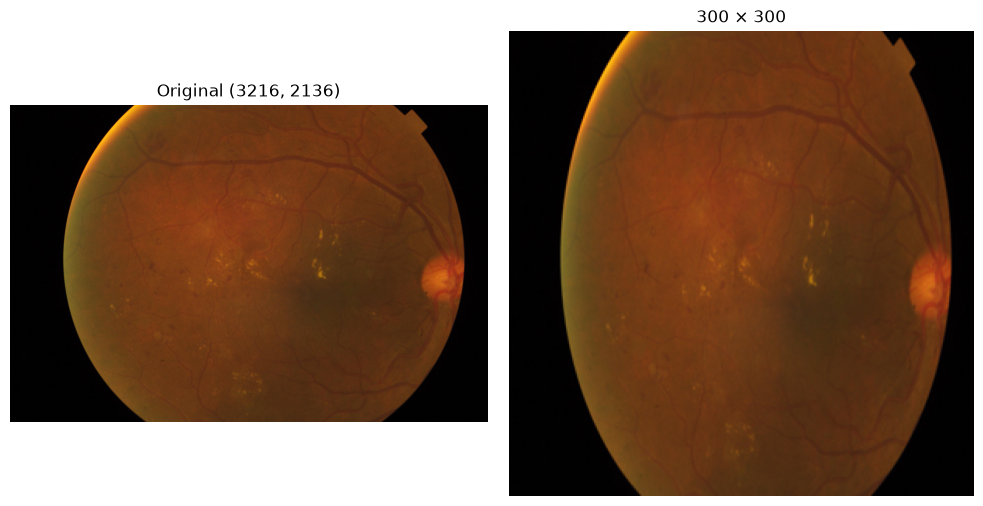

In [6]:
image_id = df.iloc[0]["id_code"]
path = os.path.join(image_folder, image_id + ".png")

image = Image.open(path).convert("RGB")
resized = image.resize((300, 300))

print("Original:", image.size)
print("Resized:", resized.size)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title(f"Original {image.size}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized)
plt.title("300 × 300")
plt.axis("off")

plt.tight_layout()
plt.show()

Original shape: (2136, 3216, 3)


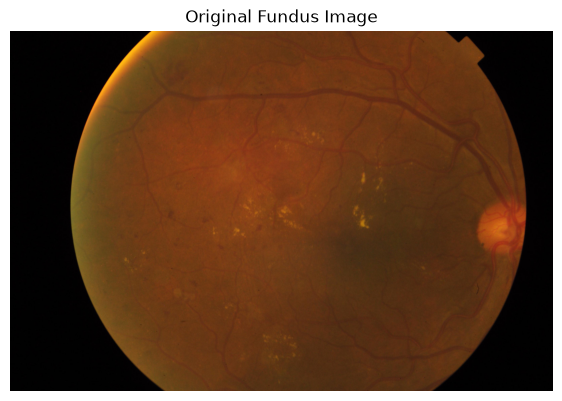

In [7]:
import cv2

image_id = df.iloc[0]["id_code"]
image_path = os.path.join(image_folder, image_id + ".png")

image = cv2.imread(image_path)

# OpenCV loads BGR; matplotlib expects RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Original shape:", image_rgb.shape)

plt.figure(figsize=(7, 7))
plt.imshow(image_rgb)
plt.title("Original Fundus Image")
plt.axis("off")
plt.show()

In [8]:
def crop_black_border(image, threshold=10):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    mask = gray > threshold

    coords = np.argwhere(mask)

    if coords.size == 0:
        return image

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    cropped = image[y_min:y_max + 1, x_min:x_max + 1]

    return cropped

Original: (2136, 3216, 3)
Cropped: (2136, 2708, 3)


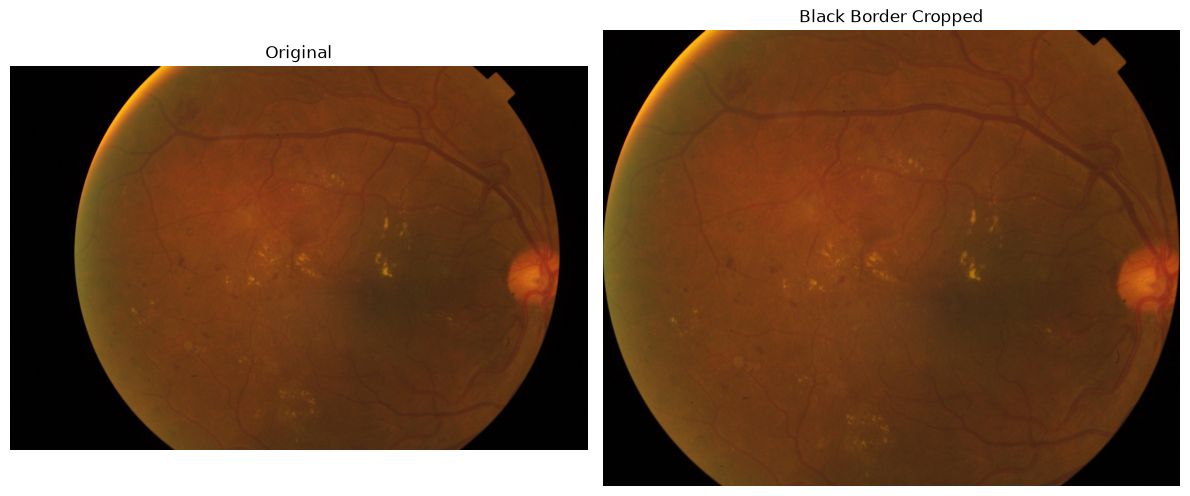

In [9]:
cropped = crop_black_border(image_rgb)

print("Original:", image_rgb.shape)
print("Cropped:", cropped.shape)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cropped)
plt.title("Black Border Cropped")
plt.axis("off")

plt.tight_layout()
plt.show()

After resizing: (300, 300, 3)


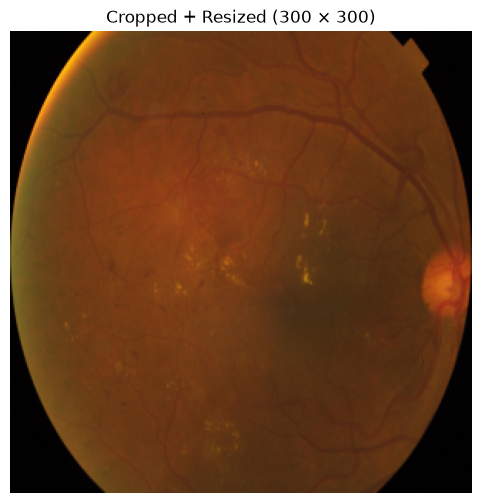

In [10]:
resized = cv2.resize(
    cropped,
    (300, 300),
    interpolation=cv2.INTER_AREA
)

print("After resizing:", resized.shape)

plt.figure(figsize=(6, 6))
plt.imshow(resized)
plt.title("Cropped + Resized (300 × 300)")
plt.axis("off")
plt.show()

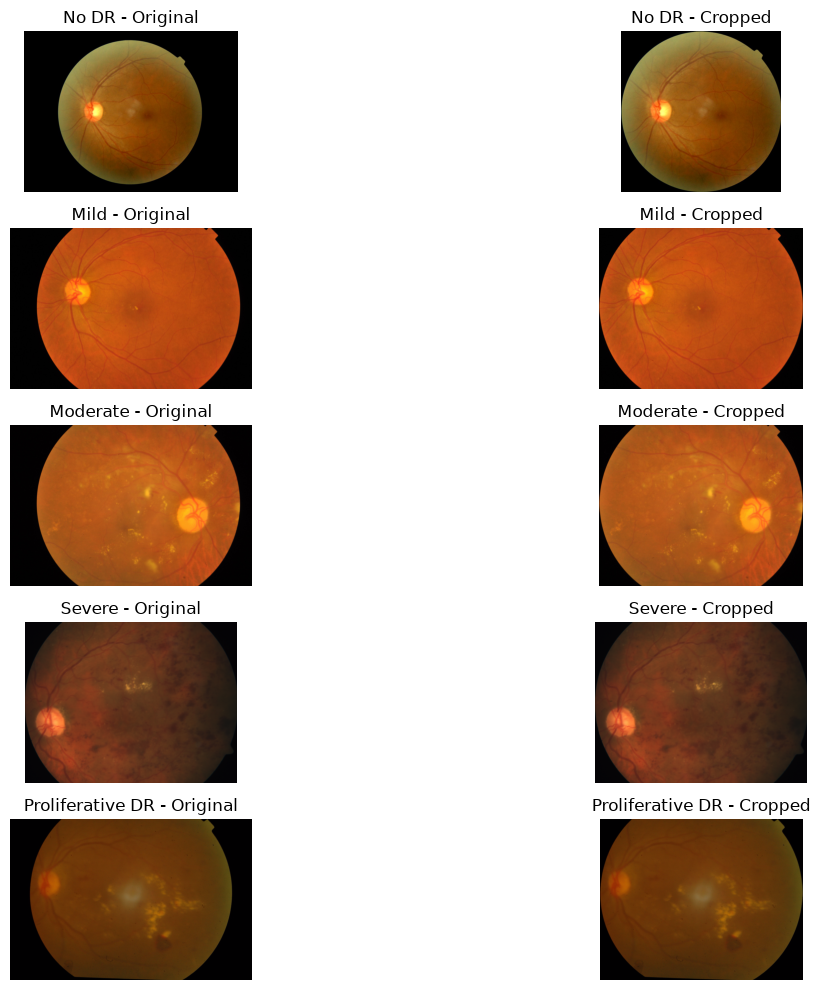

In [11]:
label_map = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

plt.figure(figsize=(15, 10))

for diagnosis in range(5):

    # Random image from this class
    sample = df[df["diagnosis"] == diagnosis].sample(1).iloc[0]

    image_id = sample["id_code"]
    image_path = os.path.join(image_folder, image_id + ".png")

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    cropped = crop_black_border(image)

    # Original
    plt.subplot(5, 2, diagnosis * 2 + 1)
    plt.imshow(image)
    plt.title(f"{label_map[diagnosis]} - Original")
    plt.axis("off")

    # Cropped
    plt.subplot(5, 2, diagnosis * 2 + 2)
    plt.imshow(cropped)
    plt.title(f"{label_map[diagnosis]} - Cropped")
    plt.axis("off")

plt.tight_layout()
plt.show()

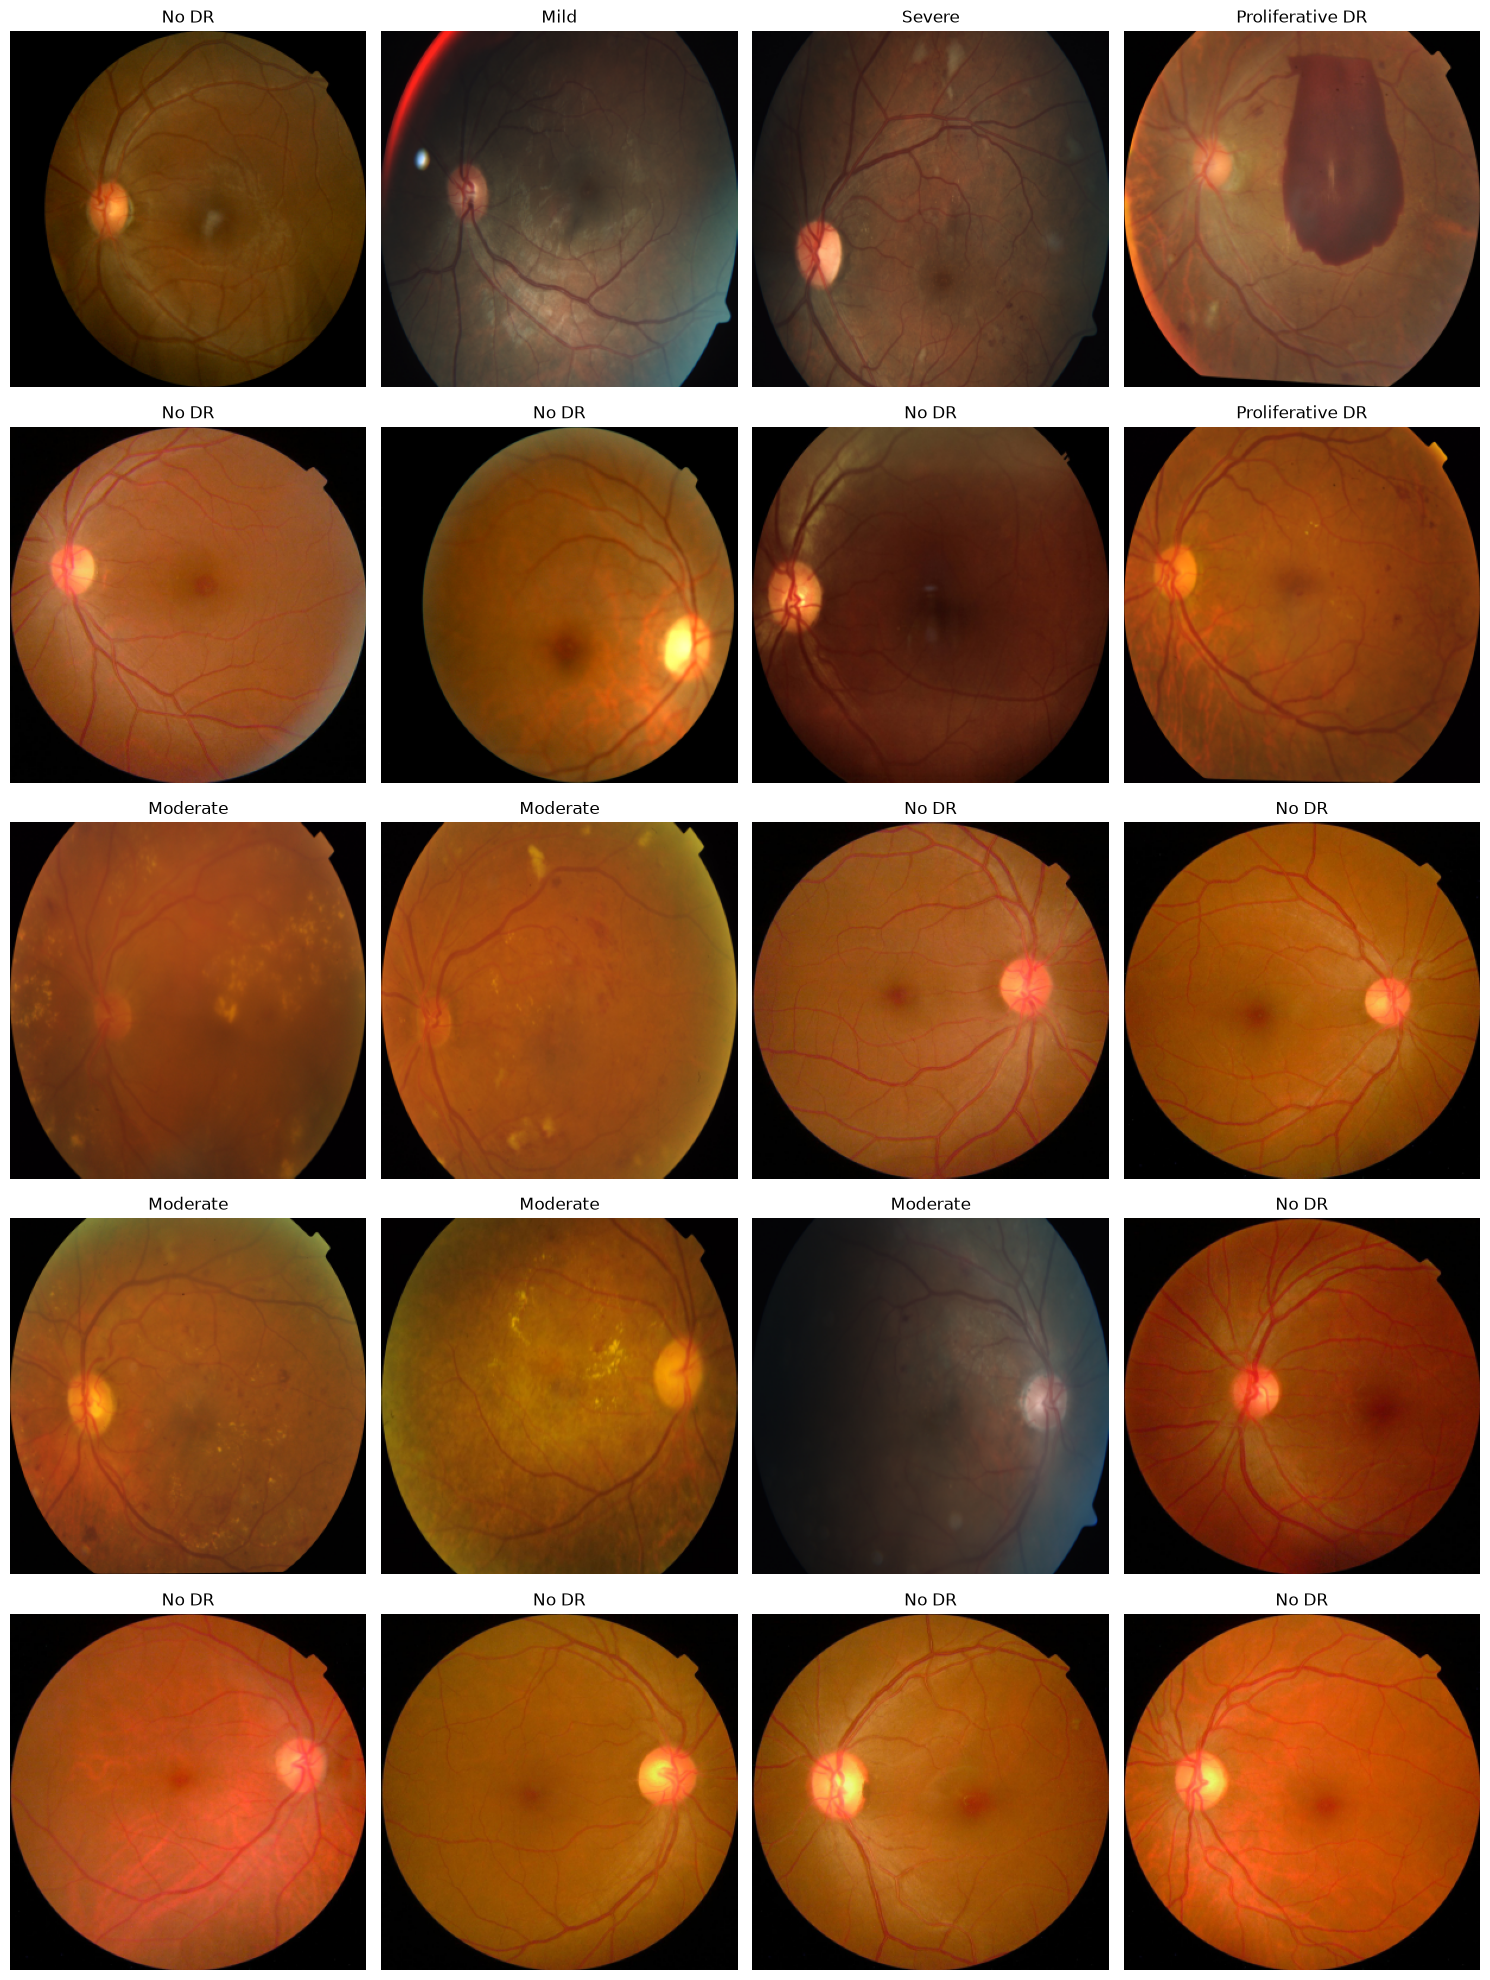

In [12]:
samples = df.sample(20, random_state=42)

plt.figure(figsize=(15, 20))

for i, (_, row) in enumerate(samples.iterrows()):

    image_path = os.path.join(
        image_folder,
        row["id_code"] + ".png"
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    cropped = crop_black_border(image)
    resized = cv2.resize(
        cropped,
        (300, 300),
        interpolation=cv2.INTER_AREA
    )

    plt.subplot(5, 4, i + 1)
    plt.imshow(resized)
    plt.title(label_map[row["diagnosis"]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["diagnosis"]
)

# Second split: temporary 20% -> 10% validation + 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["diagnosis"]
)

print("Total:", len(df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Total: 3662
Training: 2929
Validation: 366
Testing: 367


In [14]:
train_ids = set(train_df["id_code"])
val_ids = set(val_df["id_code"])
test_ids = set(test_df["id_code"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [15]:
def show_distribution(data, name):
    counts = data["diagnosis"].value_counts().sort_index()

    percentages = (
        data["diagnosis"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

    result = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2)
    })

    print(f"\n{name}")
    print(result)


show_distribution(train_df, "TRAINING SET")
show_distribution(val_df, "VALIDATION SET")
show_distribution(test_df, "TEST SET")


TRAINING SET
           Count  Percentage
diagnosis                   
0           1444       49.30
1            296       10.11
2            799       27.28
3            154        5.26
4            236        8.06

VALIDATION SET
           Count  Percentage
diagnosis                   
0            180       49.18
1             37       10.11
2            100       27.32
3             20        5.46
4             29        7.92

TEST SET
           Count  Percentage
diagnosis                   
0            181       49.32
1             37       10.08
2            100       27.25
3             19        5.18
4             30        8.17


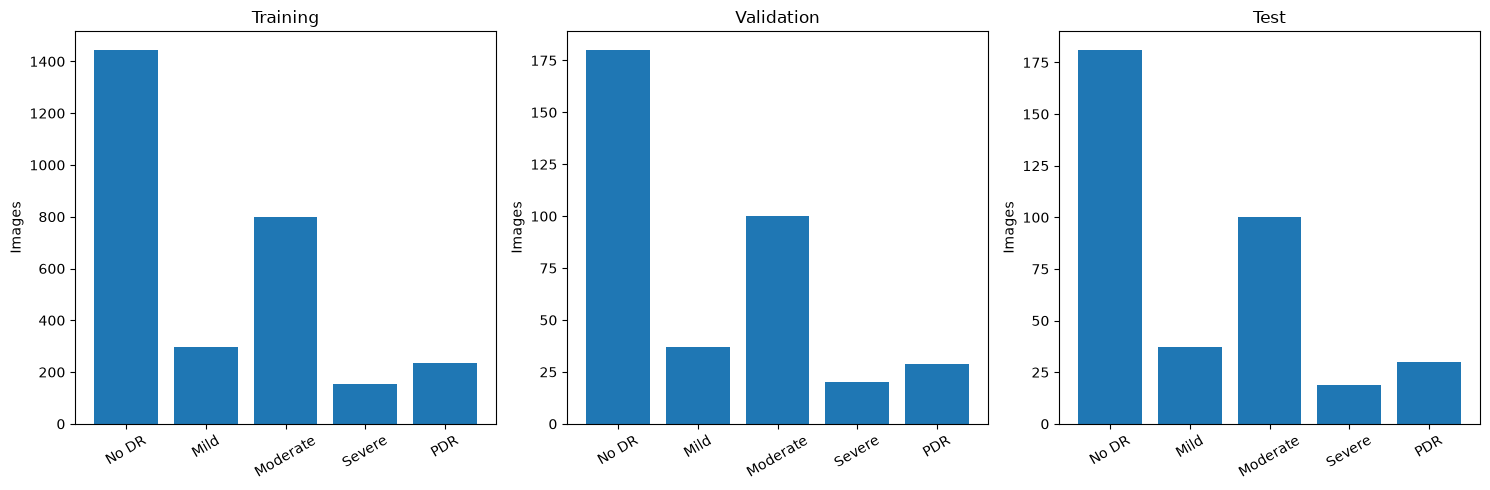

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

datasets = [
    (train_df, "Training"),
    (val_df, "Validation"),
    (test_df, "Test")
]

for ax, (data, title) in zip(axes, datasets):

    counts = (
        data["diagnosis"]
        .value_counts()
        .sort_index()
    )

    ax.bar(
        ["No DR", "Mild", "Moderate", "Severe", "PDR"],
        counts.values
    )

    ax.set_title(title)
    ax.set_ylabel("Images")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [17]:
os.makedirs("../dataset/splits", exist_ok=True)

train_df.to_csv(
    "../dataset/splits/train_split.csv",
    index=False
)

val_df.to_csv(
    "../dataset/splits/val_split.csv",
    index=False
)

test_df.to_csv(
    "../dataset/splits/test_split.csv",
    index=False
)

print("Splits saved successfully!")

Splits saved successfully!


In [5]:
import pandas as pd

train_df = pd.read_csv("../dataset/splits/train_split.csv")
val_df = pd.read_csv("../dataset/splits/val_split.csv")
test_df = pd.read_csv("../dataset/splits/test_split.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (2929, 2)
Validation: (366, 2)
Test: (367, 2)


In [10]:
import sys

if ".." not in sys.path:
    sys.path.append("..")

from model.datasets import DRDataset
from preprocessing.augment import get_train_transform, get_val_transform

print("Imports successful!")

Imports successful!


In [13]:
train_dataset = DRDataset(
    dataframe=train_df,
    image_dir="../dataset/train_images",
    transform=get_train_transform()
)

val_dataset = DRDataset(
    dataframe=val_df,
    image_dir="../dataset/train_images",
    transform=get_val_transform()
)

test_dataset = DRDataset(
    dataframe=test_df,
    image_dir="../dataset/train_images",
    transform=get_val_transform()
)
print("Datasets created successfully!")

Datasets created successfully!


In [8]:
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2929
Validation: 366
Test: 367


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

In [ ]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Labels:", labels)

print("\nImage dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("\nMinimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

In [14]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image dtype:", image.dtype)
print("Minimum value:", image.min().item())
print("Maximum value:", image.max().item())

Image shape: torch.Size([3, 300, 300])
Label: tensor(0)
Image dtype: torch.float32
Minimum value: -2.0494048595428467
Maximum value: 2.248908281326294
